# Validador de materiales y prestaciones PMS vs AGP

Herramienta operativa para comparar el PMS original contra el archivo `data` generado desde AGP.


## Casos con varios AGP o varios protocolos

El validador soporta estas dos situaciones dentro del archivo `data`:

- Un solo AGP con varios protocolos.
- Dos o más AGP, cada uno con uno o varios protocolos.

Cuando el proyecto tenga dos o más AGP, deben unirse todos en un solo archivo `data` / resumen de proyecto antes de ejecutar la validación. La estructura esperada es la misma del ejemplo `data_2000139288_2000139289.xlsx`:

```text
AGP 1
  Protocolo 1
    UT / CIT
      Materiales y prestaciones
AGP 2
  Protocolo 2
    UT / CIT
      Materiales y prestaciones
```

La comparación final se hace consolidada por `TIPO` y `CODIGO`, pero la hoja `AGP_Normalizado` conserva los AGP y protocolos asociados a cada código para auditoría.

## Aclaración importante para casos E1

Antes de cargar un PMS E1, revise cuidadosamente la columna `TIPO DE MOVIMIENTO` en `RG36_MAT`:

- Los registros `Material de aportación` se excluyen porque no deben valorizarse.
- Los materiales con movimiento `Retirado` se comparan con cantidad negativa.
- Revise especialmente los materiales de chatarra: en ocasiones corresponden a un retiro, pero el formato no queda marcado correctamente por quien lo diligencia.
- Corrija el PMS antes de ejecutar el análisis si el tipo de movimiento no representa lo realizado. La herramienta aplica la regla según lo que esté registrado en el archivo.

Esta revisión previa permite afinar los materiales de aportación y retirados para obtener un análisis de valorización confiable.

## Uso

1. Abra el notebook en Google Colab.
2. Seleccione **Entorno de ejecución > Ejecutar todas**.
3. Autorice a Colab para acceder al Google Drive de la cuenta activa.
4. Cargue el PMS cuando aparezca el primer selector.
5. Cargue el archivo `data` de AGP en el segundo selector.
6. Si el PMS es RG11 y el maestro no existe en Drive, cargue `MAT APORT_VF_1.xlsx`.
7. Revise el semáforo y el Excel descargado.

Toda la operación se ejecuta desde `main()`.

## Google Drive y permisos

- Colab solicitará autorización estándar para montar `Mi unidad`.
- El código no usa contraseñas, cuentas de servicio ni credenciales compartidas.
- La carpeta predeterminada es `Mi unidad/AGP_Validacion`.
- El maestro se busca allí y, si se carga manualmente, queda guardado para futuras ejecuciones.
- Los resultados también se conservan en `AGP_Validacion/Resultados`.

> **Regla clave:** los materiales de aportación no deben valorizarse. Se excluyen de la comparación y quedan en `Materiales_Aportacion_Excluidos`.




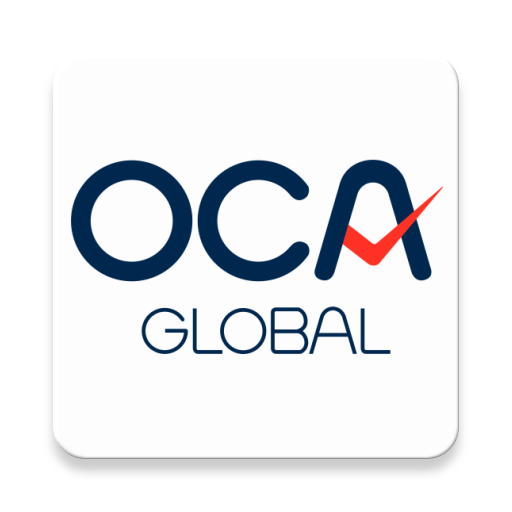

In [13]:
# @title
# Preparación mínima del entorno antes de cargar main().
import importlib.util
import subprocess
import sys

faltantes = [
    paquete
    for paquete, modulo in (("pandas", "pandas"), ("openpyxl", "openpyxl"))
    if importlib.util.find_spec(modulo) is None
]
if faltantes:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", *faltantes]
    )
print("Entorno listo.")


Entorno listo.


## Código del validador

Incluye la lectura de PMS, la estructura AGP actual de cinco niveles, compatibilidad histórica, normalización de retirados E1, comparación, auditoría y exportación.


In [17]:
"""Validacion operativa de materiales y prestaciones PMS vs AGP.

El modulo esta pensado para ejecutarse dentro de Google Colab, pero sus
funciones de lectura, comparacion y exportacion tambien funcionan localmente.
"""

from __future__ import annotations

import base64
import importlib.util
import math
import os
import re
import shutil
import subprocess
import sys
import tempfile
import unicodedata
from datetime import datetime
from pathlib import Path
from typing import Any, Iterable
from zipfile import ZIP_DEFLATED, ZipFile

import openpyxl
import pandas as pd
from openpyxl.formatting.rule import FormulaRule
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter
from xml.etree import ElementTree as ET
from openpyxl.drawing.image import Image as ExcelImage


TIPO_RG11 = "RG11_budget (flujo nuevo / viejo fuera de E1)"
TIPO_E1 = "Flujo viejo E1 (RG10_SER + RG36_MAT)"
TIPO_PRESTACION = "MDO/PRESTACION"
TIPO_MATERIAL = "MAT"
TOLERANCIA_CANTIDAD = 1e-6
_ARCHIVOS_EXCEL_SANITIZADOS: dict[str, str] = {}
_OCA_LOGO_BASE64 = "..."

COLUMNAS_ERROR = ["FUENTE", "HOJA", "FILA", "CAMPO", "VALOR", "MENSAJE"]
COLUMNAS_CRUDO = [
    "FUENTE",
    "TIPO",
    "CODIGO",
    "DESCRIPCION",
    "CANTIDAD",
    "ERROR_DATO",
    "HOJA",
    "FILA",
]
COLUMNAS_EXCLUIDOS = [
    "FUENTE",
    "TIPO",
    "CODIGO",
    "DESCRIPCION",
    "CANTIDAD",
    "MOTIVO_EXCLUSION",
    "HOJA",
    "FILA",
]
COLUMNAS_PMS = [
    "FUENTE",
    "TIPO",
    "CODIGO",
    "DESCRIPCION",
    "CANTIDAD_PMS",
    "ERROR_DATO",
]
COLUMNAS_AGP = [
    "FUENTE",
    "TIPO",
    "CODIGO",
    "DESCRIPCION",
    "CANTIDAD_AGP",
    "ERROR_DATO",
]
COLUMNAS_COMPARACION = [
    "TIPO",
    "CODIGO",
    "DESCRIPCION_PMS",
    "CANTIDAD_PMS",
    "DESCRIPCION_AGP",
    "CANTIDAD_AGP",
    "DIFERENCIA",
    "ESTADO_VALIDACION",
    "OBSERVACION",
]


class ErrorValidacion(Exception):
    """Error controlado que debe mostrarse al usuario con lenguaje simple."""


def _crear_copia_excel_sin_defined_names_corruptos(ruta_archivo: str) -> str:
    """Crea una copia temporal removiendo nombres definidos corruptos.

    Algunos RG11 traen metadatos internos de impresion/nombres definidos con
    valores como #REF! o #N/A. Excel los abre, pero openpyxl falla antes de
    permitir leer las hojas. El contenido de las hojas no se modifica.
    """
    ruta = Path(ruta_archivo)
    clave = f"{ruta.resolve()}::{ruta.stat().st_mtime_ns}"
    if clave in _ARCHIVOS_EXCEL_SANITIZADOS:
        return _ARCHIVOS_EXCEL_SANITIZADOS[clave]

    destino = Path(tempfile.gettempdir()) / (
        f"{ruta.stem}_openpyxl_limpio_{abs(hash(clave))}{ruta.suffix}"
    )
    ns_uri = "http://schemas.openxmlformats.org/spreadsheetml/2006/main"
    ET.register_namespace("", ns_uri)
    with ZipFile(ruta, "r") as entrada, ZipFile(
        destino, "w", ZIP_DEFLATED
    ) as salida:
        for info in entrada.infolist():
            datos = entrada.read(info.filename)
            if info.filename == "xl/workbook.xml":
                root = ET.fromstring(datos)
                defined_names = root.find(f"{{{ns_uri}}}definedNames")
                if defined_names is not None:
                    for defined_name in list(defined_names):
                        texto = defined_name.text or ""
                        nombre = defined_name.attrib.get("name", "")
                        es_corrupto = (
                            "#REF!" in texto
                            or "#N/A" in texto
                            or "Excel_BuiltIn_Print" in nombre
                            or nombre in {"_xlnm.Print_Titles", "_xlnm.Print_Area"}
                        )
                        if es_corrupto:
                            defined_names.remove(defined_name)
                    if len(list(defined_names)) == 0:
                        root.remove(defined_names)
                datos = ET.tostring(root, encoding="utf-8", xml_declaration=True)
            salida.writestr(info, datos)

    _ARCHIVOS_EXCEL_SANITIZADOS[clave] = str(destino)
    return str(destino)


def _cargar_workbook_seguro(ruta_archivo: str, **kwargs: Any) -> openpyxl.Workbook:
    """Abre un Excel; si tiene metadatos corruptos, usa una copia saneada."""
    try:
        return openpyxl.load_workbook(ruta_archivo, **kwargs)
    except ValueError as exc:
        mensaje = str(exc)
        requiere_limpieza = (
            "could not assign names" in mensaje
            or "print titles definition" in mensaje
            or "invalid XML" in mensaje
        )
        if not requiere_limpieza:
            raise
        ruta_limpia = _crear_copia_excel_sin_defined_names_corruptos(ruta_archivo)
        return openpyxl.load_workbook(ruta_limpia, **kwargs)


def instalar_dependencias_si_colab() -> None:
    """Instala solo las dependencias ausentes cuando se ejecuta en Colab."""
    if not en_google_colab():
        return
    faltantes = []
    for paquete, modulo in (("pandas", "pandas"), ("openpyxl", "openpyxl")):
        if importlib.util.find_spec(modulo) is None:
            faltantes.append(paquete)
    if faltantes:
        print("Instalando dependencias necesarias...")
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "-q", *faltantes]
        )


def en_google_colab() -> bool:
    try:
        return importlib.util.find_spec("google.colab") is not None
    except ModuleNotFoundError:
        return False


def montar_google_drive(carpeta_drive: str) -> Path:
    """Monta el Drive del usuario y crea la carpeta operativa configurada."""
    if not en_google_colab():
        raise ErrorValidacion(
            "Esta funcion debe ejecutarse en Google Colab para montar Google Drive."
        )
    from google.colab import drive

    print("Google solicitara permiso para acceder al Drive de esta cuenta.")
    drive.mount("/content/drive", force_remount=False)
    carpeta = Path(carpeta_drive)
    carpeta.mkdir(parents=True, exist_ok=True)
    return carpeta


def localizar_maestro_drive(carpeta_drive: str, nombre_maestro: str) -> str | None:
    """Busca el maestro primero por nombre exacto y luego por nombre aproximado."""
    carpeta = Path(carpeta_drive)
    exacto = carpeta / nombre_maestro
    if exacto.is_file():
        return str(exacto)
    if not carpeta.is_dir():
        return None
    candidatos = sorted(
        p
        for p in carpeta.glob("*.xls*")
        if "MAT" in p.name.upper() and "APORT" in p.name.upper()
    )
    return str(candidatos[0]) if candidatos else None


def cargar_un_archivo_colab(etiqueta: str, carpeta: str = "/content/cargas_agp") -> str:
    """Abre el selector de Colab y guarda exactamente un archivo cargado."""
    if not en_google_colab():
        raise ErrorValidacion(
            "La carga interactiva solo esta disponible en Google Colab."
        )
    from google.colab import files

    print(f"\nSeleccione el archivo {etiqueta}.")
    cargados = files.upload()
    if not cargados:
        raise ErrorValidacion(f"No se cargo el archivo {etiqueta}.")
    if len(cargados) > 1:
        print("Se cargaron varios archivos; se usara el primero.")
    nombre, contenido = next(iter(cargados.items()))
    destino = Path(carpeta)
    destino.mkdir(parents=True, exist_ok=True)
    ruta = destino / Path(nombre).name
    ruta.write_bytes(contenido)
    print(f"Archivo cargado: {ruta.name}")
    return str(ruta)


def cargar_archivos_colab() -> tuple[str, str]:
    """Solicita PMS y AGP en dos pasos para evitar confundir sus roles."""
    ruta_pms = cargar_un_archivo_colab("original de PMS")
    ruta_agp = cargar_un_archivo_colab(
        "generado desde AGP (normalmente data.xlsx)"
    )
    return ruta_pms, ruta_agp


def descargar_archivo_colab(ruta: str) -> None:
    if en_google_colab():
        from google.colab import files

        files.download(ruta)


def copiar_resultado_a_drive(ruta_salida: str, carpeta_drive: str) -> str | None:
    """Conserva una copia fechada del resultado en Drive."""
    if not Path(carpeta_drive).is_dir():
        return None
    carpeta_resultados = Path(carpeta_drive) / "Resultados"
    carpeta_resultados.mkdir(parents=True, exist_ok=True)
    marca = datetime.now().strftime("%Y%m%d_%H%M%S")
    origen = Path(ruta_salida)
    destino = carpeta_resultados / (
        f"{origen.stem}_{marca}{origen.suffix or '.xlsx'}"
    )
    shutil.copy2(ruta_salida, destino)
    return str(destino)


def _sin_acentos(valor: Any) -> str:
    texto = "" if valor is None else str(valor)
    return "".join(
        caracter
        for caracter in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caracter)
    )


def normalizar_encabezado(valor: Any) -> str:
    texto = _sin_acentos(valor).upper().replace("\n", " ")
    texto = re.sub(r"[^A-Z0-9]+", " ", texto)
    return re.sub(r"\s+", " ", texto).strip()


def normalizar_codigo(valor: Any) -> str:
    """Convierte el codigo a texto sin perder ceros cuando Excel los conserva."""
    if valor is None or (isinstance(valor, float) and math.isnan(valor)):
        return ""
    if isinstance(valor, bool):
        return str(valor).upper()
    if isinstance(valor, int):
        return str(valor)
    if isinstance(valor, float):
        if math.isfinite(valor) and valor.is_integer():
            return str(int(valor))
        return format(valor, "f").rstrip("0").rstrip(".")
    texto = str(valor).replace("\u00a0", " ").strip()
    texto = re.sub(r"\s+", "", texto)
    if re.fullmatch(r"[+-]?\d+\.0+", texto):
        texto = texto.split(".", 1)[0]
    return texto.upper()


def normalizar_cantidad(valor: Any) -> float | None:
    """Convierte formatos 1, 1.0, 1,0, 1,5 y negativos con signo final."""
    if valor is None or (isinstance(valor, float) and math.isnan(valor)):
        return None
    if isinstance(valor, bool):
        return float(valor)
    if isinstance(valor, (int, float)):
        numero = float(valor)
        return numero if math.isfinite(numero) else None

    texto = str(valor).strip().replace("\u00a0", "").replace(" ", "")
    if not texto:
        return None
    if texto.endswith("-") and texto.count("-") == 1:
        texto = "-" + texto[:-1]

    if "," in texto and "." in texto:
        if texto.rfind(",") > texto.rfind("."):
            texto = texto.replace(".", "").replace(",", ".")
        else:
            texto = texto.replace(",", "")
    elif "," in texto:
        texto = texto.replace(",", ".")
    elif texto.count(".") > 1:
        partes = texto.split(".")
        texto = "".join(partes[:-1]) + "." + partes[-1]

    try:
        numero = float(texto)
    except (TypeError, ValueError):
        return None
    return numero if math.isfinite(numero) else None


def listar_hojas_excel(ruta_archivo: str) -> list[str]:
    try:
        wb = _cargar_workbook_seguro(
            ruta_archivo, read_only=True, data_only=True, keep_links=False
        )
        hojas = wb.sheetnames
        wb.close()
        return hojas
    except Exception as exc:
        raise ErrorValidacion(
            f"No fue posible leer las hojas de {Path(ruta_archivo).name}: {exc}"
        ) from exc


def detectar_tipo_pms(ruta_archivo: str) -> str:
    hojas = {hoja.strip() for hoja in listar_hojas_excel(ruta_archivo)}
    if "RG11_budget" in hojas:
        return TIPO_RG11
    if {"RG10_SER", "RG36_MAT"}.issubset(hojas):
        return TIPO_E1
    raise ErrorValidacion(
        "No se pudo detectar el tipo de archivo PMS. Verifique que el archivo "
        "tenga la hoja RG11_budget o las hojas RG10_SER y RG36_MAT."
    )


def _registrar_error(
    errores: list[dict[str, Any]],
    fuente: str,
    hoja: str,
    fila: int | str | None,
    campo: str,
    valor: Any,
    mensaje: str,
) -> None:
    errores.append(
        {
            "FUENTE": fuente,
            "HOJA": hoja,
            "FILA": fila,
            "CAMPO": campo,
            "VALOR": "" if valor is None else str(valor),
            "MENSAJE": mensaje,
        }
    )


def _buscar_fila_encabezados(
    ws: openpyxl.worksheet.worksheet.Worksheet,
    grupos_requeridos: Iterable[Iterable[str]],
    max_filas: int = 40,
) -> tuple[int, dict[str, int]]:
    grupos = [
        {normalizar_encabezado(alias) for alias in grupo}
        for grupo in grupos_requeridos
    ]
    for numero_fila, fila in enumerate(
        ws.iter_rows(min_row=1, max_row=min(ws.max_row, max_filas), values_only=True),
        start=1,
    ):
        encabezados: dict[str, int] = {}
        for indice, valor in enumerate(fila):
            nombre = normalizar_encabezado(valor)
            if nombre and nombre not in encabezados:
                encabezados[nombre] = indice
        if all(any(alias in encabezados for alias in grupo) for grupo in grupos):
            return numero_fila, encabezados
    requeridos = [" / ".join(sorted(grupo)) for grupo in grupos]
    raise ErrorValidacion(
        f"No se encontraron los encabezados requeridos en la hoja {ws.title}: "
        + "; ".join(requeridos)
    )


def _indice_columna(encabezados: dict[str, int], aliases: Iterable[str]) -> int | None:
    for alias in aliases:
        indice = encabezados.get(normalizar_encabezado(alias))
        if indice is not None:
            return indice
    return None


def _tipo_desde_codigo(codigo: str) -> str:
    return TIPO_MATERIAL if re.fullmatch(r"\d+", codigo) else TIPO_PRESTACION


def _registro_crudo(
    fuente: str,
    tipo: str,
    codigo: str,
    descripcion: Any,
    cantidad: float | None,
    error_dato: bool,
    hoja: str,
    fila: int,
) -> dict[str, Any]:
    return {
        "FUENTE": fuente,
        "TIPO": tipo,
        "CODIGO": codigo,
        "DESCRIPCION": "" if descripcion is None else str(descripcion).strip(),
        "CANTIDAD": cantidad,
        "ERROR_DATO": bool(error_dato),
        "HOJA": hoja,
        "FILA": fila,
    }


def leer_pms_rg11_budget(
    ruta_archivo: str, errores: list[dict[str, Any]] | None = None
) -> pd.DataFrame:
    errores = errores if errores is not None else []
    try:
        wb = _cargar_workbook_seguro(
            ruta_archivo, read_only=True, data_only=True, keep_links=False
        )
        if "RG11_budget" not in wb.sheetnames:
            wb.close()
            raise ErrorValidacion("No se encontro la hoja RG11_budget.")
        ws = wb["RG11_budget"]
        fila_header, headers = _buscar_fila_encabezados(
            ws,
            [
                ("cod_prest/mat", "codigo", "cod prest mat"),
                ("quantity", "cantidad"),
            ],
        )
        idx_codigo = _indice_columna(
            headers, ("cod_prest/mat", "codigo", "cod prest mat")
        )
        idx_cantidad = _indice_columna(headers, ("quantity", "cantidad"))
        idx_descripcion = _indice_columna(
            headers, ("DESP", "descripcion", "texto breve de material")
        )
        registros = []
        for numero_fila, fila in enumerate(
            ws.iter_rows(min_row=fila_header + 1, values_only=True),
            start=fila_header + 1,
        ):
            valor_codigo = fila[idx_codigo] if idx_codigo is not None else None
            valor_cantidad = fila[idx_cantidad] if idx_cantidad is not None else None
            if valor_codigo is None and valor_cantidad is None:
                continue
            codigo = normalizar_codigo(valor_codigo)
            if not codigo:
                _registrar_error(
                    errores,
                    "PMS",
                    ws.title,
                    numero_fila,
                    "CODIGO",
                    valor_codigo,
                    "Se encontro una fila con cantidad pero sin codigo.",
                )
                continue
            cantidad = normalizar_cantidad(valor_cantidad)
            error_dato = cantidad is None
            if error_dato:
                _registrar_error(
                    errores,
                    "PMS",
                    ws.title,
                    numero_fila,
                    "CANTIDAD",
                    valor_cantidad,
                    "No fue posible convertir la cantidad a numero.",
                )
            descripcion = (
                fila[idx_descripcion] if idx_descripcion is not None else ""
            )
            registros.append(
                _registro_crudo(
                    "PMS",
                    _tipo_desde_codigo(codigo),
                    codigo,
                    descripcion,
                    cantidad,
                    error_dato,
                    ws.title,
                    numero_fila,
                )
            )
        wb.close()
        if not registros:
            raise ErrorValidacion(
                "La hoja RG11_budget no contiene prestaciones o materiales legibles."
            )
        return pd.DataFrame(registros, columns=COLUMNAS_CRUDO)
    except ErrorValidacion:
        raise
    except Exception as exc:
        raise ErrorValidacion(
            f"No fue posible leer RG11_budget: {exc}"
        ) from exc


def leer_pms_e1(
    ruta_archivo: str, errores: list[dict[str, Any]] | None = None
) -> tuple[pd.DataFrame, pd.DataFrame]:
    errores = errores if errores is not None else []
    registros: list[dict[str, Any]] = []
    excluidos: list[dict[str, Any]] = []
    try:
        wb = _cargar_workbook_seguro(
            ruta_archivo, read_only=True, data_only=True, keep_links=False
        )
        faltantes = [
            hoja for hoja in ("RG10_SER", "RG36_MAT") if hoja not in wb.sheetnames
        ]
        if faltantes:
            wb.close()
            raise ErrorValidacion(
                "No se encontraron las hojas requeridas: " + ", ".join(faltantes)
            )

        ws_ser = wb["RG10_SER"]
        header_ser, headers_ser = _buscar_fila_encabezados(
            ws_ser,
            [
                ("PRESTACION",),
                ("CANTIDAD",),
            ],
        )
        idx_codigo = _indice_columna(headers_ser, ("PRESTACION",))
        idx_cantidad = _indice_columna(headers_ser, ("CANTIDAD",))
        idx_descripcion = _indice_columna(
            headers_ser, ("DESCRIPCION DE LA ACTIVIDAD", "DESCRIPCION")
        )
        for numero_fila, fila in enumerate(
            ws_ser.iter_rows(min_row=header_ser + 1, values_only=True),
            start=header_ser + 1,
        ):
            valor_codigo = fila[idx_codigo] if idx_codigo is not None else None
            valor_cantidad = fila[idx_cantidad] if idx_cantidad is not None else None
            if valor_codigo is None and valor_cantidad is None:
                continue
            codigo = normalizar_codigo(valor_codigo)
            if not codigo:
                _registrar_error(
                    errores,
                    "PMS",
                    ws_ser.title,
                    numero_fila,
                    "PRESTACION",
                    valor_codigo,
                    "Se encontro una prestacion sin codigo.",
                )
                continue
            cantidad = normalizar_cantidad(valor_cantidad)
            error_dato = cantidad is None
            if error_dato:
                _registrar_error(
                    errores,
                    "PMS",
                    ws_ser.title,
                    numero_fila,
                    "CANTIDAD",
                    valor_cantidad,
                    "No fue posible convertir la cantidad a numero.",
                )
            descripcion = (
                fila[idx_descripcion] if idx_descripcion is not None else ""
            )
            registros.append(
                _registro_crudo(
                    "PMS",
                    TIPO_PRESTACION,
                    codigo,
                    descripcion,
                    cantidad,
                    error_dato,
                    ws_ser.title,
                    numero_fila,
                )
            )

        ws_mat = wb["RG36_MAT"]
        header_mat, headers_mat = _buscar_fila_encabezados(
            ws_mat,
            [
                ("CODIGO MATERIAL E4E",),
                ("CANTIDAD",),
                ("TIPO DE MOVIMIENTO",),
            ],
        )
        idx_codigo = _indice_columna(headers_mat, ("CODIGO MATERIAL E4E",))
        idx_cantidad = _indice_columna(headers_mat, ("CANTIDAD",))
        idx_movimiento = _indice_columna(headers_mat, ("TIPO DE MOVIMIENTO",))
        idx_descripcion = _indice_columna(
            headers_mat, ("TEXTO BREVE DE MATERIAL", "DESCRIPCION")
        )
        for numero_fila, fila in enumerate(
            ws_mat.iter_rows(min_row=header_mat + 1, values_only=True),
            start=header_mat + 1,
        ):
            valor_codigo = fila[idx_codigo] if idx_codigo is not None else None
            valor_cantidad = fila[idx_cantidad] if idx_cantidad is not None else None
            if valor_codigo is None and valor_cantidad is None:
                continue
            codigo = normalizar_codigo(valor_codigo)
            if not codigo:
                _registrar_error(
                    errores,
                    "PMS",
                    ws_mat.title,
                    numero_fila,
                    "CODIGO MATERIAL E4E",
                    valor_codigo,
                    "Se encontro un material sin codigo.",
                )
                continue
            cantidad = normalizar_cantidad(valor_cantidad)
            error_dato = cantidad is None
            if error_dato:
                _registrar_error(
                    errores,
                    "PMS",
                    ws_mat.title,
                    numero_fila,
                    "CANTIDAD",
                    valor_cantidad,
                    "No fue posible convertir la cantidad a numero.",
                )
            descripcion = (
                fila[idx_descripcion] if idx_descripcion is not None else ""
            )
            movimiento = fila[idx_movimiento] if idx_movimiento is not None else ""
            movimiento_normalizado = normalizar_encabezado(movimiento)
            es_aportacion = (
                "MATERIAL DE APORTACION" in movimiento_normalizado
            )
            if es_aportacion:
                excluidos.append(
                    {
                        "FUENTE": "PMS",
                        "TIPO": TIPO_MATERIAL,
                        "CODIGO": codigo,
                        "DESCRIPCION": ""
                        if descripcion is None
                        else str(descripcion).strip(),
                        "CANTIDAD": cantidad,
                        "MOTIVO_EXCLUSION": (
                            "TIPO DE MOVIMIENTO = Material de aportacion"
                        ),
                        "HOJA": ws_mat.title,
                        "FILA": numero_fila,
                    }
                )
                continue
            if (
                not error_dato
                and cantidad is not None
                and "RETIRADO" in movimiento_normalizado
            ):
                cantidad = -abs(cantidad)
            registros.append(
                _registro_crudo(
                    "PMS",
                    TIPO_MATERIAL,
                    codigo,
                    descripcion,
                    cantidad,
                    error_dato,
                    ws_mat.title,
                    numero_fila,
                )
            )
        wb.close()
        if not registros:
            raise ErrorValidacion(
                "Las hojas RG10_SER y RG36_MAT no contienen datos legibles."
            )
        return (
            pd.DataFrame(registros, columns=COLUMNAS_CRUDO),
            pd.DataFrame(excluidos, columns=COLUMNAS_EXCLUIDOS),
        )
    except ErrorValidacion:
        raise
    except Exception as exc:
        raise ErrorValidacion(f"No fue posible leer el PMS E1: {exc}") from exc


def leer_materiales_aportacion(
    ruta_archivo: str, errores: list[dict[str, Any]] | None = None
) -> pd.DataFrame:
    errores = errores if errores is not None else []
    try:
        wb = _cargar_workbook_seguro(
            ruta_archivo, read_only=True, data_only=True, keep_links=False
        )
        mejor: tuple[Any, ...] | None = None
        for ws in wb.worksheets:
            for numero_fila, fila in enumerate(
                ws.iter_rows(min_row=1, max_row=min(ws.max_row, 30), values_only=True),
                start=1,
            ):
                nombres = [normalizar_encabezado(valor) for valor in fila]
                for prioridad, alias in enumerate(
                    ("MAT APORT", "CODIGO MATERIAL", "MATERIAL", "UBICACION")
                ):
                    if alias in nombres:
                        candidato = (prioridad, ws.title, numero_fila, nombres.index(alias))
                        if mejor is None or candidato[0] < mejor[0]:
                            mejor = candidato
        if mejor is None:
            wb.close()
            raise ErrorValidacion(
                "No se encontro una columna de codigos en el maestro de aportacion."
            )
        _, nombre_hoja, fila_header, idx_codigo = mejor
        ws = wb[nombre_hoja]
        codigos = []
        for numero_fila, fila in enumerate(
            ws.iter_rows(min_row=fila_header + 1, values_only=True),
            start=fila_header + 1,
        ):
            valor = fila[idx_codigo] if idx_codigo < len(fila) else None
            codigo = normalizar_codigo(valor)
            if codigo:
                codigos.append(codigo)
        wb.close()
        codigos = sorted(set(codigos))
        if not codigos:
            raise ErrorValidacion(
                "El maestro de aportacion no contiene codigos validos."
            )
        return pd.DataFrame({"CODIGO": codigos})
    except ErrorValidacion:
        raise
    except Exception as exc:
        raise ErrorValidacion(
            f"No fue posible leer el maestro de aportacion: {exc}"
        ) from exc


def excluir_materiales_aportacion(
    df_pms: pd.DataFrame,
    df_aportacion: pd.DataFrame,
    tipo_pms: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Excluye por maestro en RG11; E1 ya llega excluido desde su propia columna."""
    if tipo_pms != TIPO_RG11:
        return df_pms.copy(), pd.DataFrame(columns=COLUMNAS_EXCLUIDOS)
    codigos_aportacion = set(df_aportacion["CODIGO"].astype(str))
    mascara = (df_pms["TIPO"] == TIPO_MATERIAL) & df_pms["CODIGO"].isin(
        codigos_aportacion
    )
    excluidos = df_pms.loc[
        mascara,
        ["FUENTE", "TIPO", "CODIGO", "DESCRIPCION", "CANTIDAD", "HOJA", "FILA"],
    ].copy()
    excluidos.insert(
        5, "MOTIVO_EXCLUSION", "Cruce con maestro MAT APORT_VF_1"
    )
    return (
        df_pms.loc[~mascara].copy(),
        excluidos.reindex(columns=COLUMNAS_EXCLUIDOS),
    )


def _parsear_nivel_5(texto_original: Any) -> dict[str, Any]:
    if texto_original is None:
        raise ValueError("La fila nivel 5 no contiene texto.")
    texto = str(texto_original).strip()
    if not texto:
        raise ValueError("La fila nivel 5 esta vacia.")
    texto = re.sub(
        r"-\s*(T[0-3])\s*-", r" - \1 - ", texto, flags=re.IGNORECASE
    )
    partes = [parte.strip() for parte in re.split(r"\s+-\s+", texto) if parte.strip()]
    if len(partes) < 3:
        raise ValueError(
            "No se pudo separar codigo, descripcion y cantidad con el formato AGP."
        )

    codigo = normalizar_codigo(partes[0])
    if not codigo:
        raise ValueError("No se encontro el codigo en la fila nivel 5.")
    tipo = _tipo_desde_codigo(codigo)

    # La exportacion historica deja PEL/tratta al final; la cantidad es penultima.
    indice_cantidad = -2 if len(partes) >= 4 else -1
    valor_cantidad = partes[indice_cantidad]
    limite_descripcion = len(partes) + indice_cantidad
    dispersion = ""
    inicio_descripcion = 1
    if tipo == TIPO_PRESTACION and len(partes) > 1:
        if re.fullmatch(r"T[0-3]", partes[1].upper()):
            dispersion = partes[1].upper()
            inicio_descripcion = 2
        else:
            dispersion = "T0"
    descripcion = " - ".join(partes[inicio_descripcion:limite_descripcion]).strip()
    if not descripcion and len(partes) > 1:
        descripcion = partes[1]
    return {
        "TIPO": tipo,
        "CODIGO": codigo,
        "DISPERSION": dispersion,
        "DESCRIPCION": descripcion,
        "VALOR_CANTIDAD": valor_cantidad,
    }


def _unir_unicos_texto(valores: Iterable[Any], separador: str = " | ") -> str:
    unicos: list[str] = []
    for valor in valores:
        if valor is None:
            continue
        try:
            if pd.isna(valor):
                continue
        except (TypeError, ValueError):
            pass
        texto = str(valor).strip()
        if texto and texto not in unicos:
            unicos.append(texto)
    return separador.join(unicos)


def _parsear_linea_agp(texto: str) -> dict[str, str] | None:
    coincidencia = re.search(r"\b(200\d{6,})\b", texto)
    if not coincidencia:
        return None
    partes = [parte.strip() for parte in re.split(r"\s+-\s+", texto) if parte.strip()]
    codigo = coincidencia.group(1)
    descripcion = " - ".join(partes[1:]) if len(partes) > 1 else ""
    return {"AGP": codigo, "DESCRIPCION_AGP": descripcion}


def _parsear_linea_protocolo(texto: str) -> dict[str, str]:
    partes = [parte.strip() for parte in re.split(r"\s+-\s+", texto) if parte.strip()]
    return {
        "CENTRO_RESPONSABLE": partes[0] if len(partes) > 0 else "",
        "PROTOCOLO": partes[1] if len(partes) > 1 else "",
        "DESCRIPCION_PROTOCOLO": " - ".join(partes[2:]) if len(partes) > 2 else "",
    }


def _leer_filas_texto_agp(
    ws: openpyxl.worksheet.worksheet.Worksheet,
) -> list[dict[str, Any]]:
    filas: list[dict[str, Any]] = []
    for numero_fila in range(1, ws.max_row + 1):
        valores = [
            celda.value
            for celda in ws[numero_fila]
            if celda.value is not None and str(celda.value).strip()
        ]
        if not valores:
            continue
        texto = next(
            (str(valor).strip() for valor in valores if isinstance(valor, str)),
            str(valores[0]).strip(),
        )
        filas.append(
            {
                "FILA": numero_fila,
                "NIVEL": ws.row_dimensions[numero_fila].outline_level,
                "TEXTO": texto,
            }
        )
    return filas


def extraer_contexto_agp(ruta_archivo: str) -> dict[str, Any]:
    """Detecta AGP, protocolo y el nivel real de los detalles.

    La exportacion actual tiene cinco niveles conceptuales:
    nivel 1 (AGP) no tiene outline, niveles 2 a 5 usan outline 1 a 4.
    Tambien se admite la exportacion historica con detalles en outline 5.
    """
    try:
        wb = _cargar_workbook_seguro(
            ruta_archivo, read_only=False, data_only=True, keep_links=False
        )
        mejor_contexto: dict[str, Any] | None = None
        for ws in wb.worksheets:
            filas_texto = _leer_filas_texto_agp(ws)
            filas_agp = [
                {**fila, **agp}
                for fila in filas_texto
                for agp in [_parsear_linea_agp(fila["TEXTO"])]
                if agp is not None
            ]
            if not filas_agp:
                continue

            primera_agp = filas_agp[0]
            niveles_con_datos = [fila["NIVEL"] for fila in filas_texto if fila["NIVEL"] > 0]
            if not niveles_con_datos:
                continue
            nivel_detalle = max(niveles_con_datos)
            cantidad_detalles = sum(
                1 for fila in filas_texto if fila["NIVEL"] == nivel_detalle
            )
            nivel_protocolo = 1 if primera_agp["NIVEL"] == 0 else primera_agp["NIVEL"] + 1
            protocolos = [
                _parsear_linea_protocolo(fila["TEXTO"])
                for fila in filas_texto
                if fila["NIVEL"] == nivel_protocolo
            ]
            candidato = {
                "HOJA": ws.title,
                "FILA_AGP": primera_agp["FILA"],
                "NIVEL_AGP_OUTLINE": primera_agp["NIVEL"],
                "AGP": _unir_unicos_texto([fila["AGP"] for fila in filas_agp], "; "),
                "AGPS": [fila["AGP"] for fila in filas_agp],
                "DESCRIPCION_AGP": _unir_unicos_texto(
                    [fila.get("DESCRIPCION_AGP", "") for fila in filas_agp]
                ),
                "CENTRO_RESPONSABLE": _unir_unicos_texto(
                    [fila.get("CENTRO_RESPONSABLE", "") for fila in protocolos], "; "
                ),
                "PROTOCOLO": _unir_unicos_texto(
                    [fila.get("PROTOCOLO", "") for fila in protocolos], "; "
                ),
                "PROTOCOLOS": [
                    fila.get("PROTOCOLO", "")
                    for fila in protocolos
                    if fila.get("PROTOCOLO", "")
                ],
                "DESCRIPCION_PROTOCOLO": _unir_unicos_texto(
                    [fila.get("DESCRIPCION_PROTOCOLO", "") for fila in protocolos]
                ),
                "NIVEL_DETALLE_OUTLINE": nivel_detalle,
                "NIVELES_CONCEPTUALES": nivel_detalle + 1,
                "CANTIDAD_FILAS_DETALLE": cantidad_detalles,
                "TOTAL_AGPS": len(set(fila["AGP"] for fila in filas_agp)),
                "TOTAL_PROTOCOLOS": len(
                    set(fila.get("PROTOCOLO", "") for fila in protocolos if fila.get("PROTOCOLO", ""))
                ),
            }
            if (
                mejor_contexto is None
                or candidato["CANTIDAD_FILAS_DETALLE"]
                > mejor_contexto["CANTIDAD_FILAS_DETALLE"]
            ):
                mejor_contexto = candidato
        wb.close()
        if mejor_contexto is None:
            raise ErrorValidacion(
                "No se encontro un codigo AGP que empiece por 200 ni una "
                "jerarquia de niveles valida en el archivo data."
            )
        if mejor_contexto["NIVEL_DETALLE_OUTLINE"] not in (4, 5):
            raise ErrorValidacion(
                "La estructura AGP detectada no corresponde a cinco niveles "
                "actuales ni a seis niveles historicos."
            )
        return mejor_contexto
    except ErrorValidacion:
        raise
    except Exception as exc:
        raise ErrorValidacion(
            f"No fue posible identificar el AGP y su protocolo: {exc}"
        ) from exc


def leer_agp_data(
    ruta_archivo: str,
    errores: list[dict[str, Any]] | None = None,
    contexto_agp: dict[str, Any] | None = None,
) -> pd.DataFrame:
    errores = errores if errores is not None else []
    try:
        contexto_agp = contexto_agp or extraer_contexto_agp(ruta_archivo)
        wb = _cargar_workbook_seguro(
            ruta_archivo, read_only=False, data_only=True, keep_links=False
        )
        if contexto_agp["HOJA"] not in wb.sheetnames:
            wb.close()
            raise ErrorValidacion(
                "No se encontro la hoja AGP detectada durante la lectura inicial."
            )
        ws = wb[contexto_agp["HOJA"]]
        nivel_detalle = contexto_agp["NIVEL_DETALLE_OUTLINE"]
        nivel_agp = contexto_agp.get("NIVEL_AGP_OUTLINE", 0)
        nivel_protocolo = 1 if nivel_agp == 0 else nivel_agp + 1
        registros = []
        agp_actual = ""
        descripcion_agp_actual = ""
        centro_actual = ""
        protocolo_actual = ""
        descripcion_protocolo_actual = ""
        for numero_fila in range(1, ws.max_row + 1):
            nivel_fila = ws.row_dimensions[numero_fila].outline_level
            valores_fila = [
                celda.value
                for celda in ws[numero_fila]
                if celda.value is not None and str(celda.value).strip()
            ]
            texto_fila = ""
            if valores_fila:
                texto_fila = next(
                    (str(valor).strip() for valor in valores_fila if isinstance(valor, str)),
                    str(valores_fila[0]).strip(),
                )

            agp_detectado = _parsear_linea_agp(texto_fila) if texto_fila else None
            if agp_detectado and nivel_fila == nivel_agp:
                agp_actual = agp_detectado["AGP"]
                descripcion_agp_actual = agp_detectado.get("DESCRIPCION_AGP", "")
                centro_actual = ""
                protocolo_actual = ""
                descripcion_protocolo_actual = ""
                continue

            if texto_fila and nivel_fila == nivel_protocolo:
                protocolo_detectado = _parsear_linea_protocolo(texto_fila)
                centro_actual = protocolo_detectado.get("CENTRO_RESPONSABLE", "")
                protocolo_actual = protocolo_detectado.get("PROTOCOLO", "")
                descripcion_protocolo_actual = protocolo_detectado.get(
                    "DESCRIPCION_PROTOCOLO", ""
                )
                continue

            if nivel_fila != nivel_detalle:
                continue
            if not valores_fila:
                _registrar_error(
                    errores,
                    "AGP",
                    ws.title,
                    numero_fila,
                    "NIVEL DETALLE",
                    "",
                    "La fila de material o prestacion esta vacia.",
                )
                continue
            texto = texto_fila or valores_fila[0]
            try:
                item = _parsear_nivel_5(texto)
            except ValueError as exc:
                partes_visibles = [
                    parte.strip()
                    for parte in re.split(r"\s+-\s+", texto)
                    if parte.strip()
                ]
                if len(partes_visibles) < 3 and not re.match(
                    r"^(?:\d+|[A-Za-z]+\d+)\b", texto
                ):
                    # Algunas exportaciones historicas incluyen una fila de
                    # agrupacion adicional con el mismo outline del detalle.
                    continue
                _registrar_error(
                    errores,
                    "AGP",
                    ws.title,
                    numero_fila,
                    "NIVEL DETALLE",
                    texto,
                    str(exc),
                )
                continue
            cantidad = normalizar_cantidad(item["VALOR_CANTIDAD"])
            error_dato = cantidad is None
            if error_dato:
                _registrar_error(
                    errores,
                    "AGP",
                    ws.title,
                    numero_fila,
                    "CANTIDAD",
                    item["VALOR_CANTIDAD"],
                    "No fue posible convertir la cantidad a numero.",
                )
            registro = _registro_crudo(
                "AGP",
                item["TIPO"],
                item["CODIGO"],
                item["DESCRIPCION"],
                cantidad,
                error_dato,
                ws.title,
                numero_fila,
            )
            registro.update(
                {
                    "AGP": agp_actual,
                    "DESCRIPCION_AGP": descripcion_agp_actual,
                    "CENTRO_RESPONSABLE": centro_actual,
                    "PROTOCOLO": protocolo_actual,
                    "DESCRIPCION_PROTOCOLO": descripcion_protocolo_actual,
                }
            )
            registros.append(registro)
        wb.close()
        if not registros:
            raise ErrorValidacion(
                "No se pudo extraer ningun material o prestacion del quinto "
                "nivel conceptual de AGP."
            )
        return pd.DataFrame(registros)
    except ErrorValidacion:
        raise
    except Exception as exc:
        raise ErrorValidacion(
            "No fue posible leer el archivo AGP. Verifique que sea el archivo "
            f"data exportado desde AGP. Detalle: {exc}"
        ) from exc


def _unir_descripciones(valores: pd.Series) -> str:
    unicos = []
    for valor in valores:
        texto = "" if pd.isna(valor) else str(valor).strip()
        if texto and texto not in unicos:
            unicos.append(texto)
    return " | ".join(unicos)


def _agrupar_normalizado(df: pd.DataFrame, fuente: str) -> pd.DataFrame:
    columna_cantidad = "CANTIDAD_PMS" if fuente == "PMS" else "CANTIDAD_AGP"
    columnas = COLUMNAS_PMS if fuente == "PMS" else COLUMNAS_AGP
    if df.empty:
        return pd.DataFrame(columns=columnas)
    agregaciones: dict[str, Any] = {
        "DESCRIPCION": ("DESCRIPCION", _unir_descripciones),
        "CANTIDAD": ("CANTIDAD", lambda serie: serie.sum(min_count=1)),
        "ERROR_DATO": ("ERROR_DATO", "max"),
    }
    if fuente == "AGP":
        for columna in ("AGP", "PROTOCOLO", "CENTRO_RESPONSABLE"):
            if columna in df.columns:
                agregaciones[columna] = (
                    columna,
                    lambda serie: _unir_unicos_texto(serie, "; "),
                )
        if "DESCRIPCION_AGP" in df.columns:
            agregaciones["DESCRIPCION_PROYECTO_AGP"] = (
                "DESCRIPCION_AGP",
                lambda serie: _unir_unicos_texto(serie, " | "),
            )
        if "DESCRIPCION_PROTOCOLO" in df.columns:
            agregaciones["DESCRIPCION_PROTOCOLO"] = (
                "DESCRIPCION_PROTOCOLO",
                lambda serie: _unir_unicos_texto(serie, " | "),
            )
    agrupado = (
        df.groupby(["TIPO", "CODIGO"], as_index=False, dropna=False)
        .agg(**agregaciones)
        .sort_values(["TIPO", "CODIGO"], kind="stable")
        .reset_index(drop=True)
    )
    agrupado.insert(0, "FUENTE", fuente)
    agrupado = agrupado.rename(columns={"CANTIDAD": columna_cantidad})
    if fuente == "AGP":
        columnas = [
            "FUENTE",
            "AGP",
            "PROTOCOLO",
            "CENTRO_RESPONSABLE",
            "TIPO",
            "CODIGO",
            "DESCRIPCION",
            columna_cantidad,
            "ERROR_DATO",
            "DESCRIPCION_PROYECTO_AGP",
            "DESCRIPCION_PROTOCOLO",
        ]
    return agrupado.reindex(columns=columnas)


def comparar_pms_vs_agp(
    df_pms: pd.DataFrame,
    df_agp: pd.DataFrame,
    tolerancia: float = TOLERANCIA_CANTIDAD,
) -> pd.DataFrame:
    pms = df_pms.rename(
        columns={
            "DESCRIPCION": "DESCRIPCION_PMS",
            "ERROR_DATO": "ERROR_PMS",
        }
    ).drop(columns=["FUENTE"], errors="ignore")
    agp = df_agp.rename(
        columns={
            "DESCRIPCION": "DESCRIPCION_AGP",
            "ERROR_DATO": "ERROR_AGP",
        }
    ).drop(columns=["FUENTE"], errors="ignore")
    combinado = pms.merge(
        agp, on=["TIPO", "CODIGO"], how="outer", indicator=True
    )
    combinado["ERROR_PMS"] = combinado["ERROR_PMS"].fillna(False).astype(bool)
    combinado["ERROR_AGP"] = combinado["ERROR_AGP"].fillna(False).astype(bool)
    combinado["DIFERENCIA"] = (
        combinado["CANTIDAD_AGP"] - combinado["CANTIDAD_PMS"]
    )

    estados = []
    observaciones = []
    for _, fila in combinado.iterrows():
        if fila["ERROR_PMS"] or fila["ERROR_AGP"]:
            estado = "ERROR_DATO"
            observacion = "No fue posible convertir una cantidad a numero."
        elif fila["_merge"] == "left_only":
            estado = "SOLO_EN_PMS"
            observacion = "El codigo esta en PMS pero no fue valorizado en AGP."
        elif fila["_merge"] == "right_only":
            estado = "SOLO_EN_AGP"
            observacion = "El codigo fue valorizado en AGP pero no existe en PMS."
        elif abs(float(fila["DIFERENCIA"])) <= tolerancia:
            estado = "OK"
            observacion = "Coincide correctamente."
        else:
            estado = "DIFERENCIA_CANTIDAD"
            observacion = "Cantidad diferente entre PMS y AGP."
        estados.append(estado)
        observaciones.append(observacion)
    combinado["ESTADO_VALIDACION"] = estados
    combinado["OBSERVACION"] = observaciones
    return (
        combinado.reindex(columns=COLUMNAS_COMPARACION)
        .sort_values(["ESTADO_VALIDACION", "TIPO", "CODIGO"], kind="stable")
        .reset_index(drop=True)
    )


def generar_resumen(
    df_comparacion: pd.DataFrame,
    df_pms: pd.DataFrame,
    df_agp: pd.DataFrame,
    df_excluidos: pd.DataFrame,
    errores: pd.DataFrame,
    nombre_pms: str,
    nombre_agp: str,
    tipo_pms: str,
    nombre_maestro: str = "",
    contexto_agp: dict[str, Any] | None = None,
) -> tuple[pd.DataFrame, dict[str, Any]]:
    contexto_agp = contexto_agp or {}
    conteos = df_comparacion["ESTADO_VALIDACION"].value_counts().to_dict()
    total_ok = int(conteos.get("OK", 0))
    total_dif_cantidad = int(conteos.get("DIFERENCIA_CANTIDAD", 0))
    total_solo_pms = int(conteos.get("SOLO_EN_PMS", 0))
    total_solo_agp = int(conteos.get("SOLO_EN_AGP", 0))
    total_error_dato = int(conteos.get("ERROR_DATO", 0))
    total_diferencias = (
        total_dif_cantidad + total_solo_pms + total_solo_agp + total_error_dato
    )
    total_errores = len(errores)
    if total_errores:
        resultado = (
            "Validacion incompleta: se encontraron errores de lectura o "
            "estructura. Revise la hoja Errores."
        )
        semaforo = "ERROR"
    elif total_diferencias:
        resultado = (
            "Validacion con diferencias: revise el Excel generado antes de "
            "enviar el caso."
        )
        semaforo = "ADVERTENCIA"
    else:
        resultado = (
            "Validacion OK: PMS y AGP coinciden. No se detectaron diferencias "
            "en materiales o prestaciones valorizables."
        )
        semaforo = "OK"
    datos = {
        "FECHA_HORA_VALIDACION": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "ARCHIVO_PMS": nombre_pms,
        "ARCHIVO_AGP": nombre_agp,
        "CODIGO_AGP": contexto_agp.get("AGP", "No detectado"),
        "DESCRIPCION_AGP": contexto_agp.get("DESCRIPCION_AGP", ""),
        "CENTRO_RESPONSABLE": contexto_agp.get("CENTRO_RESPONSABLE", ""),
        "PROTOCOLO": contexto_agp.get("PROTOCOLO", "No detectado"),
        "TOTAL_AGPS_DETECTADOS": contexto_agp.get("TOTAL_AGPS", "No detectado"),
        "TOTAL_PROTOCOLOS_DETECTADOS": contexto_agp.get(
            "TOTAL_PROTOCOLOS", "No detectado"
        ),
        "DESCRIPCION_PROTOCOLO": contexto_agp.get(
            "DESCRIPCION_PROTOCOLO", ""
        ),
        "NIVELES_CONCEPTUALES_AGP": contexto_agp.get(
            "NIVELES_CONCEPTUALES", "No detectado"
        ),
        "TIPO_PMS_DETECTADO": tipo_pms,
        "MAESTRO_APORTACION": nombre_maestro or "No aplica",
        "TOTAL_CODIGOS_PMS": len(df_pms),
        "TOTAL_CODIGOS_AGP": len(df_agp),
        "TOTAL_OK": total_ok,
        "TOTAL_DIFERENCIAS_CANTIDAD": total_dif_cantidad,
        "TOTAL_SOLO_PMS": total_solo_pms,
        "TOTAL_SOLO_AGP": total_solo_agp,
        "TOTAL_ERROR_DATO": total_error_dato,
        "TOTAL_CON_DIFERENCIAS": total_diferencias,
        "TOTAL_APORTACION_EXCLUIDOS": (
            int(df_excluidos["CODIGO"].nunique()) if not df_excluidos.empty else 0
        ),
        "TOTAL_ERRORES_REGISTRADOS": total_errores,
        "RESULTADO_GENERAL": resultado,
        "SEMAFORO": semaforo,
    }
    resumen = pd.DataFrame(
        [{"INDICADOR": clave, "VALOR": valor} for clave, valor in datos.items()]
    )
    return resumen, datos


def _df_errores(errores: list[dict[str, Any]]) -> pd.DataFrame:
    return pd.DataFrame(errores, columns=COLUMNAS_ERROR)


def _limpiar_merges(ws: openpyxl.worksheet.worksheet.Worksheet) -> None:
    for rango in list(ws.merged_cells.ranges):
        ws.unmerge_cells(str(rango))


def _aplicar_borde_rango(
    ws: openpyxl.worksheet.worksheet.Worksheet,
    min_row: int,
    max_row: int,
    min_col: int,
    max_col: int,
    estilo_externo: str = "medium",
    estilo_interno: str = "thin",
) -> None:
    for fila in range(min_row, max_row + 1):
        for columna in range(min_col, max_col + 1):
            celda = ws.cell(fila, columna)
            celda.border = Border(
                left=Side(
                    style=estilo_externo if columna == min_col else estilo_interno,
                    color="000000",
                ),
                right=Side(
                    style=estilo_externo if columna == max_col else estilo_interno,
                    color="000000",
                ),
                top=Side(
                    style=estilo_externo if fila == min_row else estilo_interno,
                    color="000000",
                ),
                bottom=Side(
                    style=estilo_externo if fila == max_row else estilo_interno,
                    color="000000",
                ),
            )


def _insertar_logo_oca(ws: openpyxl.worksheet.worksheet.Worksheet) -> None:
    if not _OCA_LOGO_BASE64 or _OCA_LOGO_BASE64.startswith("__"):
        return
    logo_path = Path(tempfile.gettempdir()) / "oca_global_logo_agp.png"
    if not logo_path.exists():
        logo_path.write_bytes(base64.b64decode(_OCA_LOGO_BASE64))
    logo = ExcelImage(str(logo_path))
    logo.width = 72
    logo.height = 72
    logo.anchor = "A1"
    ws.add_image(logo)


def _aplicar_cabecera_hseq(
    ws: openpyxl.worksheet.worksheet.Worksheet,
    numero_hoja: int,
    total_hojas: int,
    ultima_columna: int,
) -> None:
    ultima_columna = max(ultima_columna, 3)
    _limpiar_merges(ws)
    ws.merge_cells("A1:A4")
    if ultima_columna > 2:
        ws.merge_cells(start_row=1, start_column=2, end_row=2, end_column=ultima_columna - 1)
        ws.merge_cells(start_row=3, start_column=2, end_row=4, end_column=ultima_columna - 1)

    ws["A1"] = None
    ws["B1"] = "FORMATO"
    ws["B3"] = "SALIDA VALIDACION AGP"
    ws.cell(1, ultima_columna).value = "F-AGP-07"
    ws.cell(2, ultima_columna).value = "Rev.01"
    ws.cell(3, ultima_columna).value = "Fecha: 14/07/2026"
    ws.cell(4, ultima_columna).value = f"Hoja {numero_hoja} de {total_hojas}"

    for fila in range(1, 5):
        ws.row_dimensions[fila].height = 15
        for columna in range(1, ultima_columna + 1):
            celda = ws.cell(fila, columna)
            celda.font = Font(name="Arial", size=11, bold=False, color="000000")
            celda.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
            celda.fill = PatternFill(fill_type=None)
    ws["B1"].font = Font(name="Arial", size=11, bold=True, color="000000")
    ws["B3"].font = Font(name="Arial", size=11, bold=True, color="000000")
    _aplicar_borde_rango(ws, 1, 4, 1, ultima_columna, "medium", "thin")
    ws.column_dimensions["A"].width = max(ws.column_dimensions["A"].width or 0, 18)
    _insertar_logo_oca(ws)


def _aplicar_control_cambios(wb: openpyxl.Workbook, total_hojas: int) -> None:
    if "Control Cambios" in wb.sheetnames:
        del wb["Control Cambios"]
    ws = wb.create_sheet("Control Cambios")
    ws.sheet_view.showGridLines = False
    _aplicar_cabecera_hseq(ws, total_hojas, total_hojas, 10)
    ws.merge_cells("A5:J5")
    ws.merge_cells("B6:D6")
    ws.merge_cells("F6:G6")
    ws.merge_cells("H6:I6")
    ws.merge_cells("B7:D7")
    ws.merge_cells("F7:G7")
    ws.merge_cells("H7:I7")
    ws.merge_cells("B8:D8")
    ws.merge_cells("F8:G8")
    ws.merge_cells("H8:I8")
    encabezado_fill = PatternFill("solid", fgColor="035771")
    headers = {
        "A6": "VERSION",
        "B6": "CONTROL DE CAMBIOS DEL DOCUMENTO",
        "E6": "FECHA",
        "F6": "ELABORO",
        "H6": "REVISO",
        "J6": "APROBO",
    }
    for celda, valor in headers.items():
        ws[celda] = valor
        ws[celda].fill = encabezado_fill
        ws[celda].font = Font(name="Arial", size=11, bold=True, color="FFFFFF")
        ws[celda].alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws["A7"] = "01"
    ws["B7"] = "Version inicial"
    ws["E7"] = datetime(2026, 7, 14)
    ws["F7"] = "Coordinador Proyecto"
    ws["H7"] = "Coordinador HSEQ"
    ws["J7"] = "Director Proyecto"
    for fila in range(7, 9):
        for columna in range(1, 11):
            celda = ws.cell(fila, columna)
            celda.font = Font(name="Arial", size=11, color="000000")
            celda.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws["E7"].number_format = "dd/mm/yyyy"
    _aplicar_borde_rango(ws, 5, 8, 1, 10, "medium", "thin")
    ws.column_dimensions["A"].width = 18
    ws.column_dimensions["B"].width = 18
    ws.column_dimensions["C"].width = 18
    ws.column_dimensions["D"].width = 18
    ws.column_dimensions["E"].width = 14
    ws.column_dimensions["F"].width = 18
    ws.column_dimensions["G"].width = 18
    ws.column_dimensions["H"].width = 18
    ws.column_dimensions["I"].width = 18
    ws.column_dimensions["J"].width = 24


def _ajustar_excel(ruta_salida: str) -> None:
    wb = _cargar_workbook_seguro(ruta_salida)
    azul = "1F4E78"
    azul_claro = "D9EAF7"
    blanco = "FFFFFF"
    borde = Side(style="thin", color="000000")
    colores_estado = {
        "OK": "C6EFCE",
        "DIFERENCIA_CANTIDAD": "FFEB9C",
        "SOLO_EN_PMS": "FCE4D6",
        "SOLO_EN_AGP": "F8CBAD",
        "ERROR_DATO": "FFC7CE",
    }
    total_hojas = 10
    orden_hojas = [
        "Resumen",
        "Comparacion",
        "PMS_Normalizado",
        "AGP_Normalizado",
        "Materiales_Aportacion_Excluidos",
        "Solo_PMS",
        "Solo_AGP",
        "Diferencias_Cantidad",
        "Errores",
    ]
    for indice_hoja, nombre_hoja in enumerate(orden_hojas, start=1):
        if nombre_hoja not in wb.sheetnames:
            continue
        ws = wb[nombre_hoja]
        ws.sheet_view.showGridLines = False
        fila_header = 7 if ws.title == "Resumen" else 5
        ultima_columna = max(ws.max_column, 3)
        _aplicar_cabecera_hseq(ws, indice_hoja, total_hojas, ultima_columna)
        ws.freeze_panes = f"A{fila_header + 1}"
        if ws.max_column and ws.max_row >= fila_header:
            if ws.title == "Resumen":
                ws.auto_filter.ref = f"A{fila_header}:B{ws.max_row}"
            else:
                ws.auto_filter.ref = (
                    f"A{fila_header}:{get_column_letter(ws.max_column)}{ws.max_row}"
                )
        for celda in ws[fila_header]:
            celda.fill = PatternFill("solid", fgColor=azul)
            celda.font = Font(name="Calibri", size=11, color=blanco, bold=True)
            celda.alignment = Alignment(horizontal="center", vertical="center")
            celda.border = Border(left=borde, right=borde, top=borde, bottom=borde)
        if ws.title == "Resumen":
            ws.merge_cells("A5:C5")
            ws.merge_cells("A6:C6")
            ws.merge_cells("B7:C7")
            ws["A5"] = "VALIDACION DE MATERIALES Y PRESTACIONES PMS VS AGP"
            ws["A5"].fill = PatternFill("solid", fgColor=azul)
            ws["A5"].font = Font(name="Arial", size=11, color=blanco, bold=True)
            ws["A5"].alignment = Alignment(horizontal="center", vertical="center")
            ws["A6"] = (
                "Los materiales de aportacion se excluyen de la comparacion y "
                "quedan registrados para auditoria."
            )
            ws["A6"].fill = PatternFill("solid", fgColor=azul_claro)
            ws["A6"].font = Font(name="Arial", size=11, color="000000")
            ws["A6"].alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
            ws.row_dimensions[5].height = 25
            ws.row_dimensions[6].height = 15
            for fila in (5, 6):
                for columna in range(1, 4):
                    ws.cell(fila, columna).border = Border(
                        left=borde, right=borde, top=borde, bottom=borde
                    )
        for columna in range(1, ws.max_column + 1):
            letra = get_column_letter(columna)
            maximo = 0
            for fila in range(1, min(ws.max_row, 500) + 1):
                valor = ws.cell(fila, columna).value
                longitud = max((len(linea) for linea in str(valor).splitlines()), default=0)
                maximo = max(maximo, longitud)
            ws.column_dimensions[letra].width = min(max(maximo + 2, 11), 45)
        for fila in ws.iter_rows(min_row=fila_header + 1):
            for celda in fila:
                celda.font = Font(name="Calibri", size=11, color="000000")
                celda.alignment = Alignment(vertical="top", wrap_text=False)
                celda.border = Border(left=borde, right=borde, top=borde, bottom=borde)

        encabezados = {
            normalizar_encabezado(ws.cell(fila_header, c).value): c
            for c in range(1, ws.max_column + 1)
        }
        for nombre in ("CANTIDAD PMS", "CANTIDAD AGP", "CANTIDAD", "DIFERENCIA"):
            indice = encabezados.get(nombre)
            if indice:
                for fila in range(fila_header + 1, ws.max_row + 1):
                    ws.cell(fila, indice).number_format = "0.######"
        indice_estado = encabezados.get("ESTADO VALIDACION")
        if indice_estado and ws.max_row > fila_header:
            letra = get_column_letter(indice_estado)
            rango = f"{letra}{fila_header + 1}:{letra}{ws.max_row}"
            for estado, color in colores_estado.items():
                ws.conditional_formatting.add(
                    rango,
                    FormulaRule(
                        formula=[f'${letra}{fila_header + 1}="{estado}"'],
                        fill=PatternFill("solid", fgColor=color),
                    ),
                )
    _aplicar_control_cambios(wb, total_hojas)
    wb._sheets = [wb[nombre] for nombre in orden_hojas if nombre in wb.sheetnames] + [wb["Control Cambios"]]
    wb.save(ruta_salida)


def exportar_excel_validacion(
    ruta_salida: str,
    resumen: pd.DataFrame,
    comparacion: pd.DataFrame,
    pms_normalizado: pd.DataFrame,
    agp_normalizado: pd.DataFrame,
    excluidos: pd.DataFrame,
    errores: pd.DataFrame,
) -> str:
    ruta = Path(ruta_salida)
    ruta.parent.mkdir(parents=True, exist_ok=True)
    solo_pms = comparacion[
        comparacion["ESTADO_VALIDACION"] == "SOLO_EN_PMS"
    ].copy()
    solo_agp = comparacion[
        comparacion["ESTADO_VALIDACION"] == "SOLO_EN_AGP"
    ].copy()
    diferencias = comparacion[
        comparacion["ESTADO_VALIDACION"] == "DIFERENCIA_CANTIDAD"
    ].copy()
    with pd.ExcelWriter(ruta, engine="openpyxl") as writer:
        resumen.to_excel(writer, sheet_name="Resumen", index=False, startrow=6)
        comparacion.to_excel(writer, sheet_name="Comparacion", index=False, startrow=4)
        pms_normalizado.to_excel(writer, sheet_name="PMS_Normalizado", index=False, startrow=4)
        agp_normalizado.to_excel(writer, sheet_name="AGP_Normalizado", index=False, startrow=4)
        excluidos.reindex(columns=COLUMNAS_EXCLUIDOS).to_excel(
            writer, sheet_name="Materiales_Aportacion_Excluidos", index=False, startrow=4
        )
        solo_pms.to_excel(writer, sheet_name="Solo_PMS", index=False, startrow=4)
        solo_agp.to_excel(writer, sheet_name="Solo_AGP", index=False, startrow=4)
        diferencias.to_excel(
            writer, sheet_name="Diferencias_Cantidad", index=False, startrow=4
        )
        errores.reindex(columns=COLUMNAS_ERROR).to_excel(
            writer, sheet_name="Errores", index=False, startrow=4
        )
    _ajustar_excel(str(ruta))
    return str(ruta)


def mostrar_resultado_operativo(
    datos_resumen: dict[str, Any], ruta_salida: str
) -> None:
    lineas = [
        f"Codigos PMS: {datos_resumen['TOTAL_CODIGOS_PMS']}",
        f"Codigos AGP: {datos_resumen['TOTAL_CODIGOS_AGP']}",
        f"OK: {datos_resumen['TOTAL_OK']}",
        f"Diferencias de cantidad: {datos_resumen['TOTAL_DIFERENCIAS_CANTIDAD']}",
        f"Solo en PMS: {datos_resumen['TOTAL_SOLO_PMS']}",
        f"Solo en AGP: {datos_resumen['TOTAL_SOLO_AGP']}",
        (
            "Materiales de aportacion excluidos: "
            f"{datos_resumen['TOTAL_APORTACION_EXCLUIDOS']}"
        ),
        f"Errores registrados: {datos_resumen['TOTAL_ERRORES_REGISTRADOS']}",
    ]
    paleta = {
        "OK": {
            "borde": "#188038",
            "fondo": "#E6F4EA",
            "titulo": "#0D652D",
            "texto": "#17351F",
        },
        "ADVERTENCIA": {
            "borde": "#F29900",
            "fondo": "#FEF7E0",
            "titulo": "#8A4B00",
            "texto": "#3D2E00",
        },
        "ERROR": {
            "borde": "#D93025",
            "fondo": "#FCE8E6",
            "titulo": "#A50E0E",
            "texto": "#4A1110",
        },
    }[datos_resumen["SEMAFORO"]]
    icono = {
        "OK": "\u2705",
        "ADVERTENCIA": "\u26a0\ufe0f",
        "ERROR": "\u274c",
    }[datos_resumen["SEMAFORO"]]
    try:
        from IPython.display import HTML, display

        items = "".join(
            f'<li style="color:{paleta["texto"]} !important;'
            f'margin:3px 0">{linea}</li>'
            for linea in lineas
        )
        display(
            HTML(
                f"""
                <div style="border:1px solid {paleta['borde']};
                            border-left:8px solid {paleta['borde']};
                            border-radius:6px;padding:16px 20px;
                            background:{paleta['fondo']} !important;
                            color:{paleta['texto']} !important;
                            margin:12px 0;font-family:Arial,sans-serif">
                  <h3 style="color:{paleta['titulo']} !important;
                             margin:0 0 10px 0;font-weight:700">
                    {icono}: {datos_resumen['RESULTADO_GENERAL']}
                  </h3>
                  <ul style="color:{paleta['texto']} !important;
                             margin:6px 0 12px 18px;padding:0">{items}</ul>
                  <p style="color:{paleta['texto']} !important;margin:0">
                    <b style="color:{paleta['texto']} !important">
                      Archivo generado:
                    </b>
                    <span style="color:{paleta['texto']} !important">
                      {Path(ruta_salida).name}
                    </span>
                  </p>
                </div>
                """
            )
        )
    except Exception:
        print(datos_resumen["RESULTADO_GENERAL"])
        for linea in lineas:
            print("-", linea)
        print("Archivo generado:", ruta_salida)


def ejecutar_validacion(
    ruta_pms: str,
    ruta_agp: str,
    ruta_maestro: str | None = None,
    ruta_salida: str | None = None,
) -> dict[str, Any]:
    """Ejecuta el flujo completo y siempre intenta producir un Excel auditable."""
    errores: list[dict[str, Any]] = []
    tipo_pms = "No detectado"
    pms_crudo = pd.DataFrame(columns=COLUMNAS_CRUDO)
    agp_crudo = pd.DataFrame(columns=COLUMNAS_CRUDO)
    excluidos = pd.DataFrame(columns=COLUMNAS_EXCLUIDOS)
    contexto_agp: dict[str, Any] = {}

    try:
        tipo_pms = detectar_tipo_pms(ruta_pms)
        if tipo_pms == TIPO_RG11:
            pms_crudo = leer_pms_rg11_budget(ruta_pms, errores)
            if not ruta_maestro or not Path(ruta_maestro).is_file():
                raise ErrorValidacion(
                    "El archivo de materiales de aportacion no fue cargado y "
                    "este flujo RG11 lo requiere."
                )
            maestro = leer_materiales_aportacion(ruta_maestro, errores)
            pms_crudo, excluidos = excluir_materiales_aportacion(
                pms_crudo, maestro, tipo_pms
            )
        else:
            pms_crudo, excluidos = leer_pms_e1(ruta_pms, errores)
    except Exception as exc:
        _registrar_error(
            errores,
            "PMS",
            "",
            "",
            "LECTURA PMS",
            Path(ruta_pms).name,
            str(exc),
        )

    try:
        contexto_agp = extraer_contexto_agp(ruta_agp)
        agp_crudo = leer_agp_data(ruta_agp, errores, contexto_agp)
    except Exception as exc:
        _registrar_error(
            errores,
            "AGP",
            "",
            "",
            "LECTURA AGP",
            Path(ruta_agp).name,
            str(exc),
        )

    pms_normalizado = _agrupar_normalizado(pms_crudo, "PMS")
    agp_normalizado = _agrupar_normalizado(agp_crudo, "AGP")
    comparacion = comparar_pms_vs_agp(pms_normalizado, agp_normalizado)
    df_errores = _df_errores(errores)
    resumen, datos_resumen = generar_resumen(
        comparacion,
        pms_normalizado,
        agp_normalizado,
        excluidos,
        df_errores,
        Path(ruta_pms).name,
        Path(ruta_agp).name,
        tipo_pms,
        (
            Path(ruta_maestro).name
            if tipo_pms == TIPO_RG11 and ruta_maestro
            else ""
        ),
        contexto_agp,
    )
    codigo_agp = contexto_agp.get("AGP", "AGP_NO_DETECTADO")
    codigo_agp_archivo = re.sub(r"[^A-Za-z0-9]+", "_", str(codigo_agp)).strip("_")
    if not codigo_agp_archivo:
        codigo_agp_archivo = "AGP_NO_DETECTADO"
    nombre_salida = (
        f"validacion_materiales_prestaciones_AGP_{codigo_agp_archivo}.xlsx"
    )
    if ruta_salida is None:
        carpeta_salida = Path("/content") if en_google_colab() else Path.cwd()
        ruta_salida = str(carpeta_salida / nombre_salida)
    elif Path(ruta_salida).suffix.lower() not in (".xlsx", ".xlsm"):
        ruta_salida = str(Path(ruta_salida) / nombre_salida)
    exportar_excel_validacion(
        ruta_salida,
        resumen,
        comparacion,
        pms_normalizado,
        agp_normalizado,
        excluidos,
        df_errores,
    )
    mostrar_resultado_operativo(datos_resumen, ruta_salida)
    return {
        "ruta_salida": ruta_salida,
        "tipo_pms": tipo_pms,
        "contexto_agp": contexto_agp,
        "resumen": resumen,
        "datos_resumen": datos_resumen,
        "comparacion": comparacion,
        "pms_normalizado": pms_normalizado,
        "agp_normalizado": agp_normalizado,
        "excluidos": excluidos,
        "errores": df_errores,
    }


def main(
    ruta_pms: str | None = None,
    ruta_agp: str | None = None,
    ruta_maestro: str | None = None,
    carpeta_trabajo_drive: str = "/content/drive/MyDrive/AGP_Validacion",
    nombre_maestro_aportacion: str = "MAT APORT_VF_1.xlsx",
    carpeta_salida: str = "/content",
    guardar_copia_en_drive: bool = True,
    descargar_resultado_automaticamente: bool = True,
) -> dict[str, Any]:
    """Punto unico de entrada para el uso operativo en Google Colab."""
    instalar_dependencias_si_colab()
    es_colab = en_google_colab()

    if es_colab:
        montar_google_drive(carpeta_trabajo_drive)
        if ruta_maestro is None:
            ruta_maestro = localizar_maestro_drive(
                carpeta_trabajo_drive, nombre_maestro_aportacion
            )
        if ruta_pms is None or ruta_agp is None:
            ruta_pms, ruta_agp = cargar_archivos_colab()
    elif ruta_pms is None or ruta_agp is None:
        raise ErrorValidacion(
            "Fuera de Google Colab debe indicar ruta_pms y ruta_agp al llamar main()."
        )

    tipo_pms = detectar_tipo_pms(ruta_pms)
    if tipo_pms == TIPO_RG11 and (
        ruta_maestro is None or not Path(ruta_maestro).is_file()
    ):
        if not es_colab:
            raise ErrorValidacion(
                "Este PMS RG11 requiere la ruta del maestro MAT APORT_VF_1.xlsx."
            )
        print(
            "Este flujo requiere el maestro de materiales de aportacion. "
            "Seleccione MAT APORT_VF_1.xlsx."
        )
        maestro_cargado = cargar_un_archivo_colab(
            "maestro MAT APORT_VF_1"
        )
        destino_maestro = (
            Path(carpeta_trabajo_drive) / nombre_maestro_aportacion
        )
        shutil.copy2(maestro_cargado, destino_maestro)
        ruta_maestro = str(destino_maestro)
        print("Maestro guardado para proximas validaciones:", ruta_maestro)

    contexto = extraer_contexto_agp(ruta_agp)
    print(
        f"AGP detectado(s): {contexto['AGP']} "
        f"({contexto.get('TOTAL_AGPS', 0)} total) | "
        f"Protocolo(s): {contexto.get('PROTOCOLO') or 'No detectado'} "
        f"({contexto.get('TOTAL_PROTOCOLOS', 0)} total) | "
        f"Estructura: {contexto['NIVELES_CONCEPTUALES']} niveles"
    )
    resultado = ejecutar_validacion(
        ruta_pms=ruta_pms,
        ruta_agp=ruta_agp,
        ruta_maestro=ruta_maestro,
        ruta_salida=carpeta_salida,
    )

    if guardar_copia_en_drive and es_colab:
        copia_drive = copiar_resultado_a_drive(
            resultado["ruta_salida"], carpeta_trabajo_drive
        )
        if copia_drive:
            print("Copia guardada en Drive:", copia_drive)
            resultado["copia_drive"] = copia_drive
    if descargar_resultado_automaticamente and es_colab:
        descargar_archivo_colab(resultado["ruta_salida"])
    return resultado


## Ejecutar

Esta es la única llamada operativa. `main()` monta Drive, carga archivos, detecta AGP y protocolo, valida, exporta, guarda y descarga el resultado.

El nombre se genera con el código encontrado en el primer nivel de `data`, por ejemplo:

`validacion_materiales_prestaciones_AGP_2000138100.xlsx`


In [15]:
resultado = main()


Google solicitara permiso para acceder al Drive de esta cuenta.
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Seleccione el archivo original de PMS.


Saving PPTO Javier Armando Rodriguez_PROBADO.xlsx to PPTO Javier Armando Rodriguez_PROBADO.xlsx
Archivo cargado: PPTO Javier Armando Rodriguez_PROBADO.xlsx

Seleccione el archivo generado desde AGP (normalmente data.xlsx).


Saving 20251206093704_4130125980284d3396163235363c94f1.xlsx to 20251206093704_4130125980284d3396163235363c94f1 (1).xlsx
Archivo cargado: 20251206093704_4130125980284d3396163235363c94f1 (1).xlsx
AGP detectado: 2000130075 | Protocolo: 1000151285 | Estructura: 6 niveles


/tmp/ipykernel_2049/838145537.py:1049: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  combinado["ERROR_AGP"] = combinado["ERROR_AGP"].fillna(False).astype(bool)


Copia guardada en Drive: /content/drive/MyDrive/AGP_Validacion/Resultados/validacion_materiales_prestaciones_AGP_2000130075_20260615_024757.xlsx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Semáforo

- **✅ Validación OK:** PMS y AGP coinciden.
- **⚠️ Validación con diferencias:** revise `Solo_PMS`, `Solo_AGP` y `Diferencias_Cantidad`.
- **❌ Validación incompleta:** revise la hoja `Errores`.

La hoja `Resumen` incluye el código AGP, protocolo, descripción y cantidad de niveles detectados.


---

© 2026 Dirección AGP. Todos los derechos reservados.

Herramienta desarrollada por **Juan Sebastián Fernández Buitrago (CAGlobal)** para la validación de materiales y prestaciones PMS vs. AGP.

Uso interno autorizado. No distribuir, modificar ni reproducir sin autorización de la Dirección AGP y del autor.
